In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

RANDOM_STATE = 42
sns.set_style('whitegrid')

In [47]:
df = pd.read_csv('winequality-red.csv', sep=';')
print(df.shape)
df.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [49]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [50]:
print(df['quality'].value_counts().sort_index())
df['good_quality'] = (df['quality'] >= 7).astype(int)
print()
print(df['good_quality'].value_counts())
print((df['good_quality'].value_counts(normalize=True) * 100).round(2))

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

good_quality
0    1382
1     217
Name: count, dtype: int64
good_quality
0    86.43
1    13.57
Name: proportion, dtype: float64


In [51]:
print(df.isnull().sum())
print('Total missing:', df.isnull().sum().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
good_quality            0
dtype: int64
Total missing: 0


In [52]:
print('Duplicates before:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicates after :', df.duplicated().sum())
print('Shape now:', df.shape)

Duplicates before: 240
Duplicates after : 0
Shape now: (1359, 13)


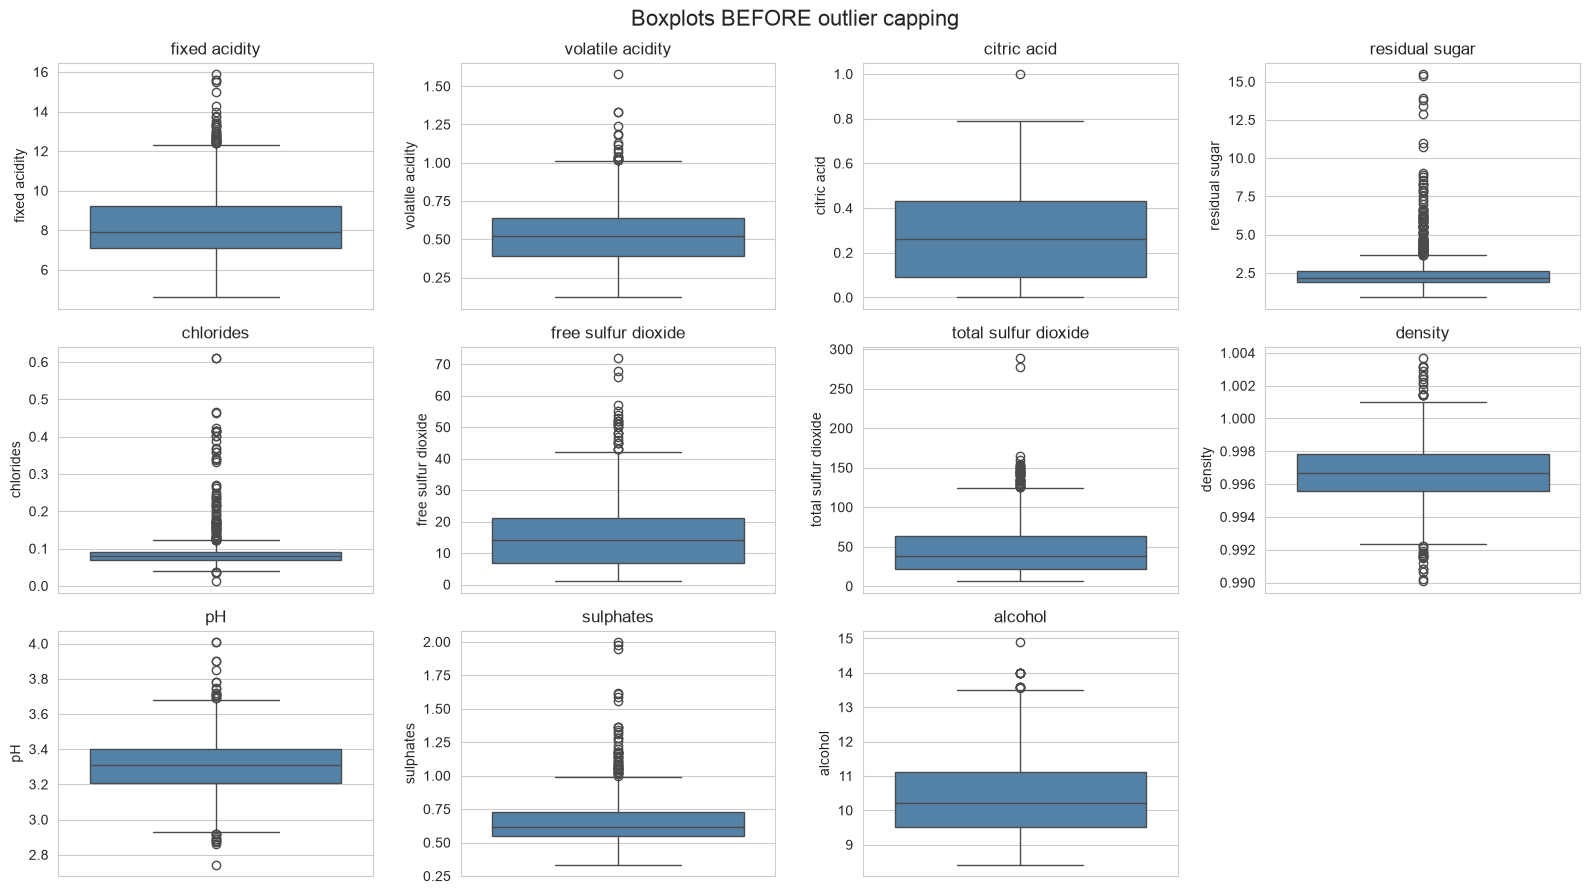

In [53]:
def cap_outliers_iqr(dataframe, exclude_columns=None):
    dataframe = dataframe.copy()
    exclude_columns = exclude_columns or []
    for col in dataframe.select_dtypes(include=np.number).columns:
        if col in exclude_columns:
            continue
        q1, q3 = dataframe[col].quantile(0.25), dataframe[col].quantile(0.75)
        iqr = q3 - q1
        dataframe[col] = dataframe[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    return dataframe

feature_cols = [c for c in df.columns if c not in ['quality', 'good_quality']]

def boxplots(data, title):
    fig, axes = plt.subplots(3, 4, figsize=(16, 9))
    for ax, col in zip(axes.ravel(), feature_cols):
        sns.boxplot(y=data[col], ax=ax, color='steelblue')
        ax.set_title(col)
    for ax in axes.ravel()[len(feature_cols):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

boxplots(df, 'Boxplots BEFORE outlier capping')

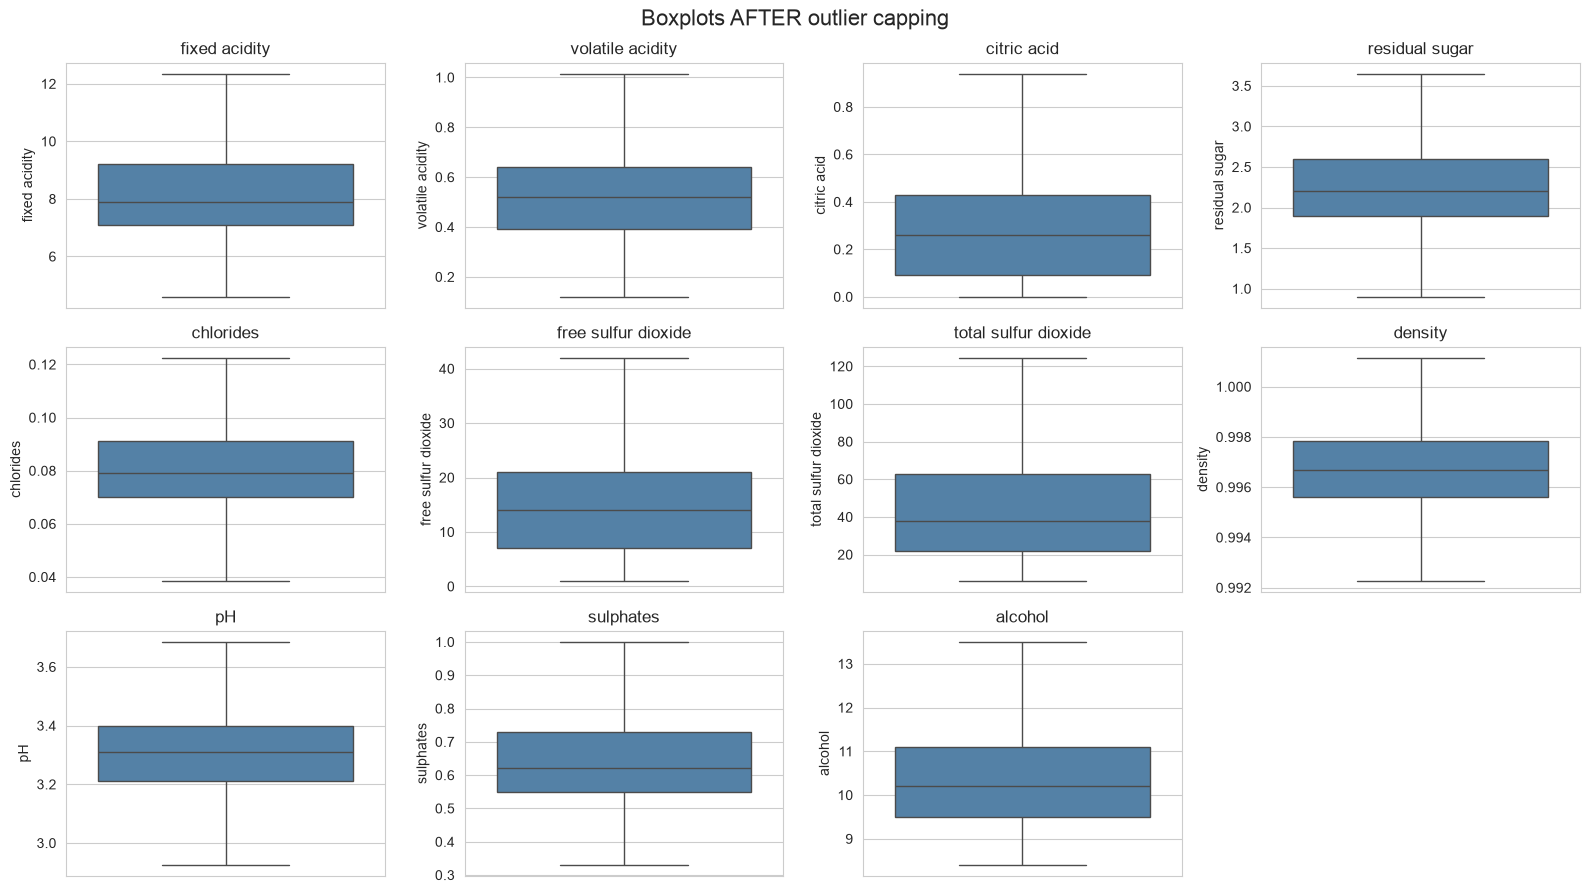

In [54]:
df_clean = cap_outliers_iqr(df, exclude_columns=['quality', 'good_quality'])
boxplots(df_clean, 'Boxplots AFTER outlier capping')

In [55]:
df_clean.columns = [c.replace(' ', '_') for c in df_clean.columns]
feature_cols = [c for c in df_clean.columns if c not in ['quality', 'good_quality']]
df_clean.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,good_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [56]:
X = df_clean[feature_cols]
y = df_clean['good_quality']
print(X.shape, y.shape)

(1359, 11) (1359,)


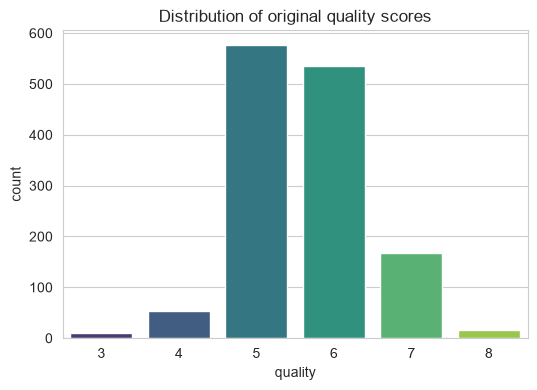

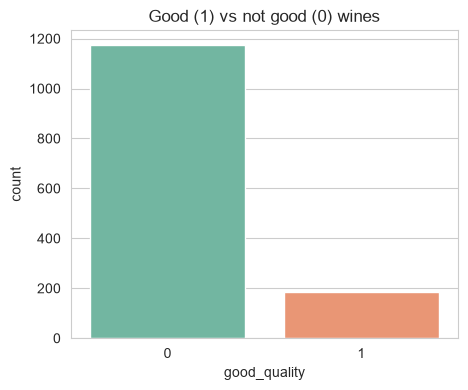

In [57]:
plt.figure(figsize=(6,4))
sns.countplot(x='quality', data=df_clean, palette='viridis')
plt.title('Distribution of original quality scores')
plt.show()

plt.figure(figsize=(5,4))
sns.countplot(x='good_quality', data=df_clean, palette='Set2')
plt.title('Good (1) vs not good (0) wines')
plt.show()

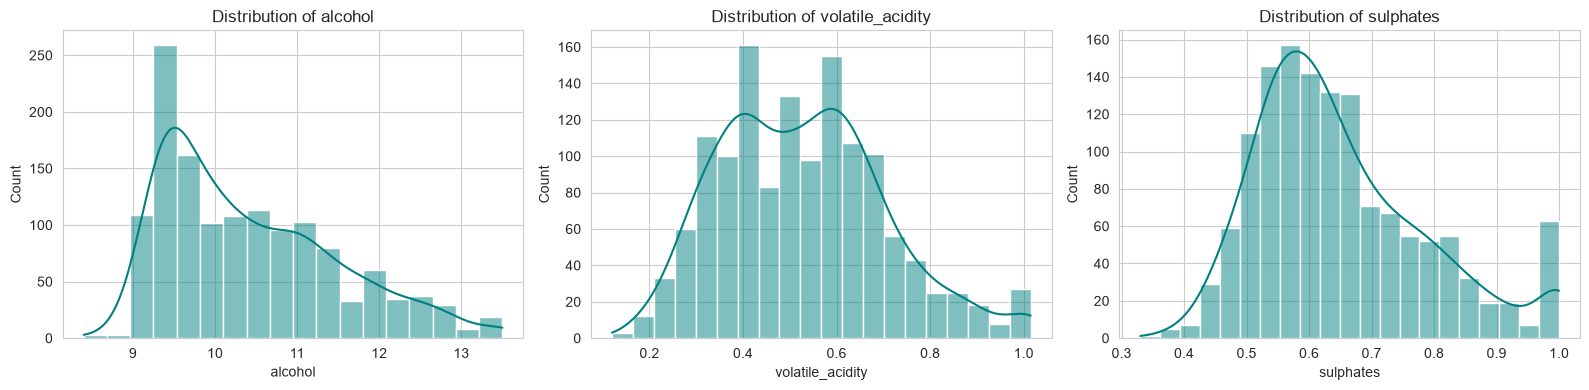

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['alcohol', 'volatile_acidity', 'sulphates']):
    sns.histplot(df_clean[col], kde=True, ax=ax, color='teal')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout(); plt.show()

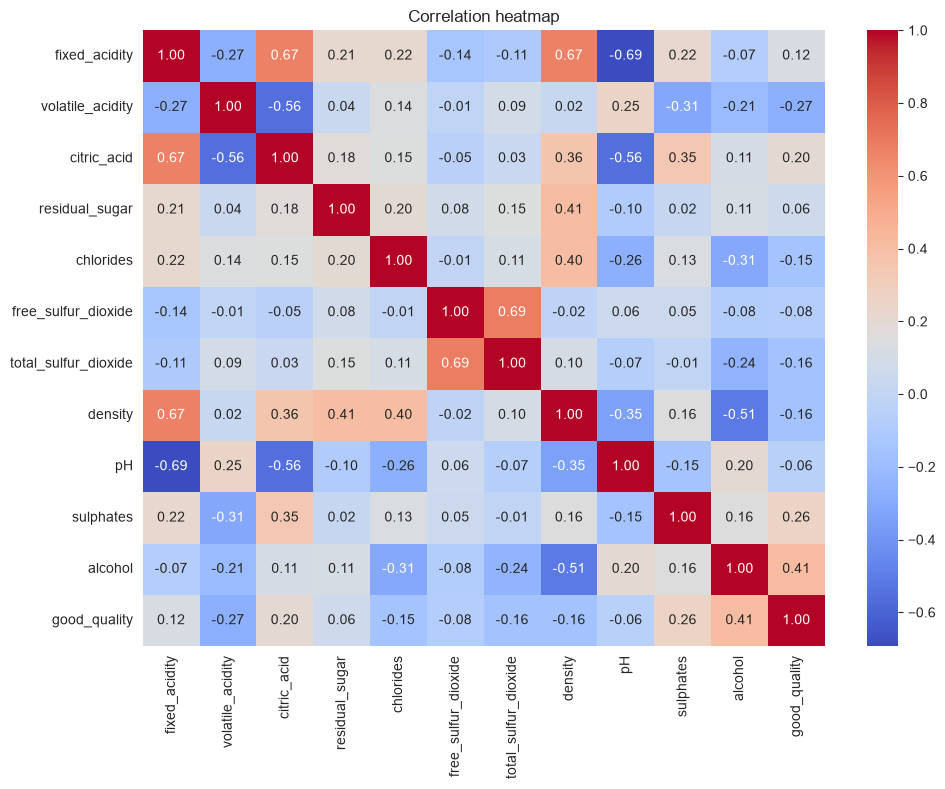

In [59]:
plt.figure(figsize=(11, 8))
sns.heatmap(df_clean[feature_cols + ['good_quality']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Good-wine share  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Train: (1087, 11)  Test: (272, 11)
Good-wine share  train: 0.135  test: 0.136


In [61]:
selector = SelectKBest(score_func=f_classif, k=8)
selector.fit(X_train, y_train)

feature_scores = pd.DataFrame({'Feature': X_train.columns, 'Score': selector.scores_}) \
                   .sort_values('Score', ascending=False).reset_index(drop=True)
display(feature_scores)

selected = X_train.columns[selector.get_support()].tolist()
print('Selected features:', selected)
X_train_sel, X_test_sel = X_train[selected], X_test[selected]

,Feature,Score
0,alcohol,215.996479
1,volatile_acidity,88.279477
2,sulphates,79.262806
3,citric_acid,56.206057
4,total_sulfur_dioxide,31.384195
5,fixed_acidity,23.355459
6,density,22.993767
7,chlorides,21.487222
8,free_sulfur_dioxide,9.630446
9,pH,7.438648


Selected features: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'chlorides', 'total_sulfur_dioxide', 'density', 'sulphates', 'alcohol']


In [62]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)

In [63]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=7),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    preds[name] = y_pred
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:, 1]),
    })

results = pd.DataFrame(rows).sort_values('F1-Score', ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7794,0.3736,0.9189,0.5312,0.8895
1,Random Forest,0.8676,0.5128,0.5405,0.5263,0.8827
2,Decision Tree,0.7904,0.3611,0.7027,0.4771,0.7893
3,KNN,0.8676,0.5172,0.4054,0.4545,0.8003


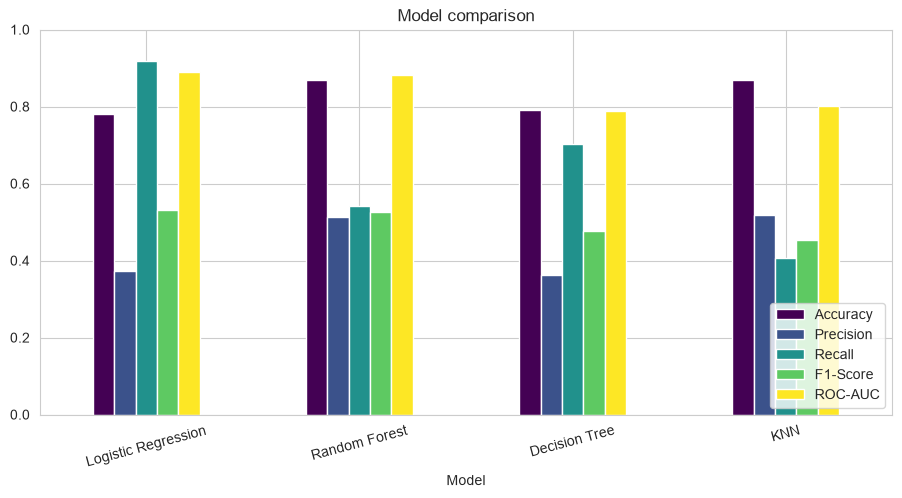

In [64]:
results.set_index('Model')[['Accuracy','Precision','Recall','F1-Score','ROC-AUC']].plot(
    kind='bar', figsize=(11, 5), colormap='viridis')
plt.title('Model comparison'); plt.ylim(0, 1); plt.xticks(rotation=15)
plt.legend(loc='lower right'); plt.show()

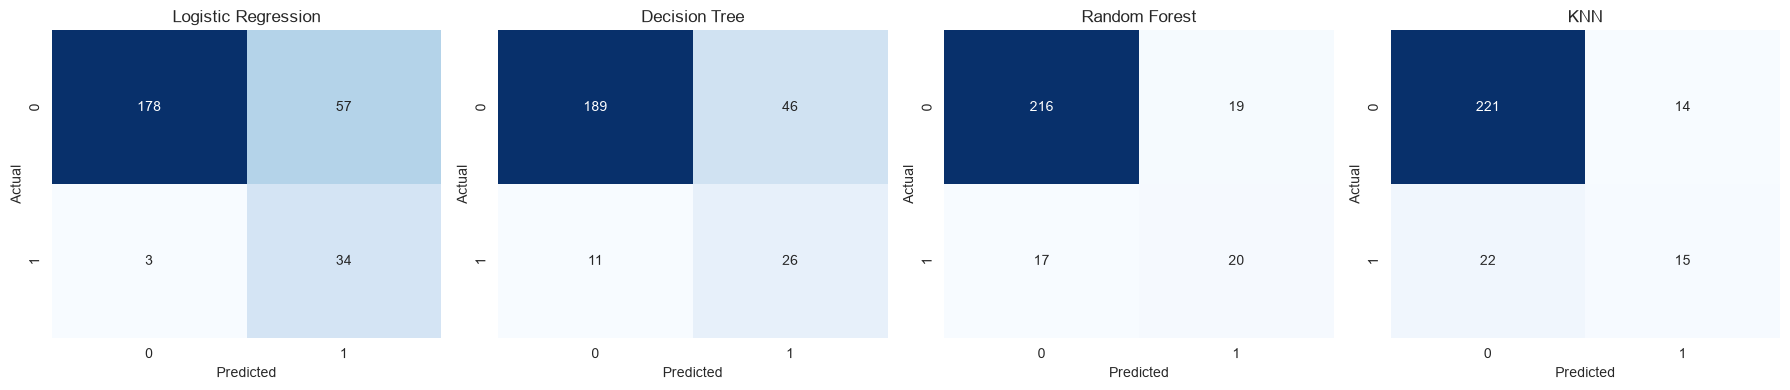

In [65]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, p) in zip(axes, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()